# **scRNA-seq analysis using Scanpy and DESeq2**
This script is adapted for the GSE150728 CELLxGENE .h5ad dataset that we discussed.
H5AD input

It will perform:
1. Download GSE150728 .h5ad data.
2. Inspect AnnData structure and expression matrix.
3. Identify available raw counts and normalized expression.
4. Calculate quality-control metrics.
5. Filter low-quality cells where appropriate.
6. Identify highly variable genes.
7. Export CSV, PNG and H5AD results

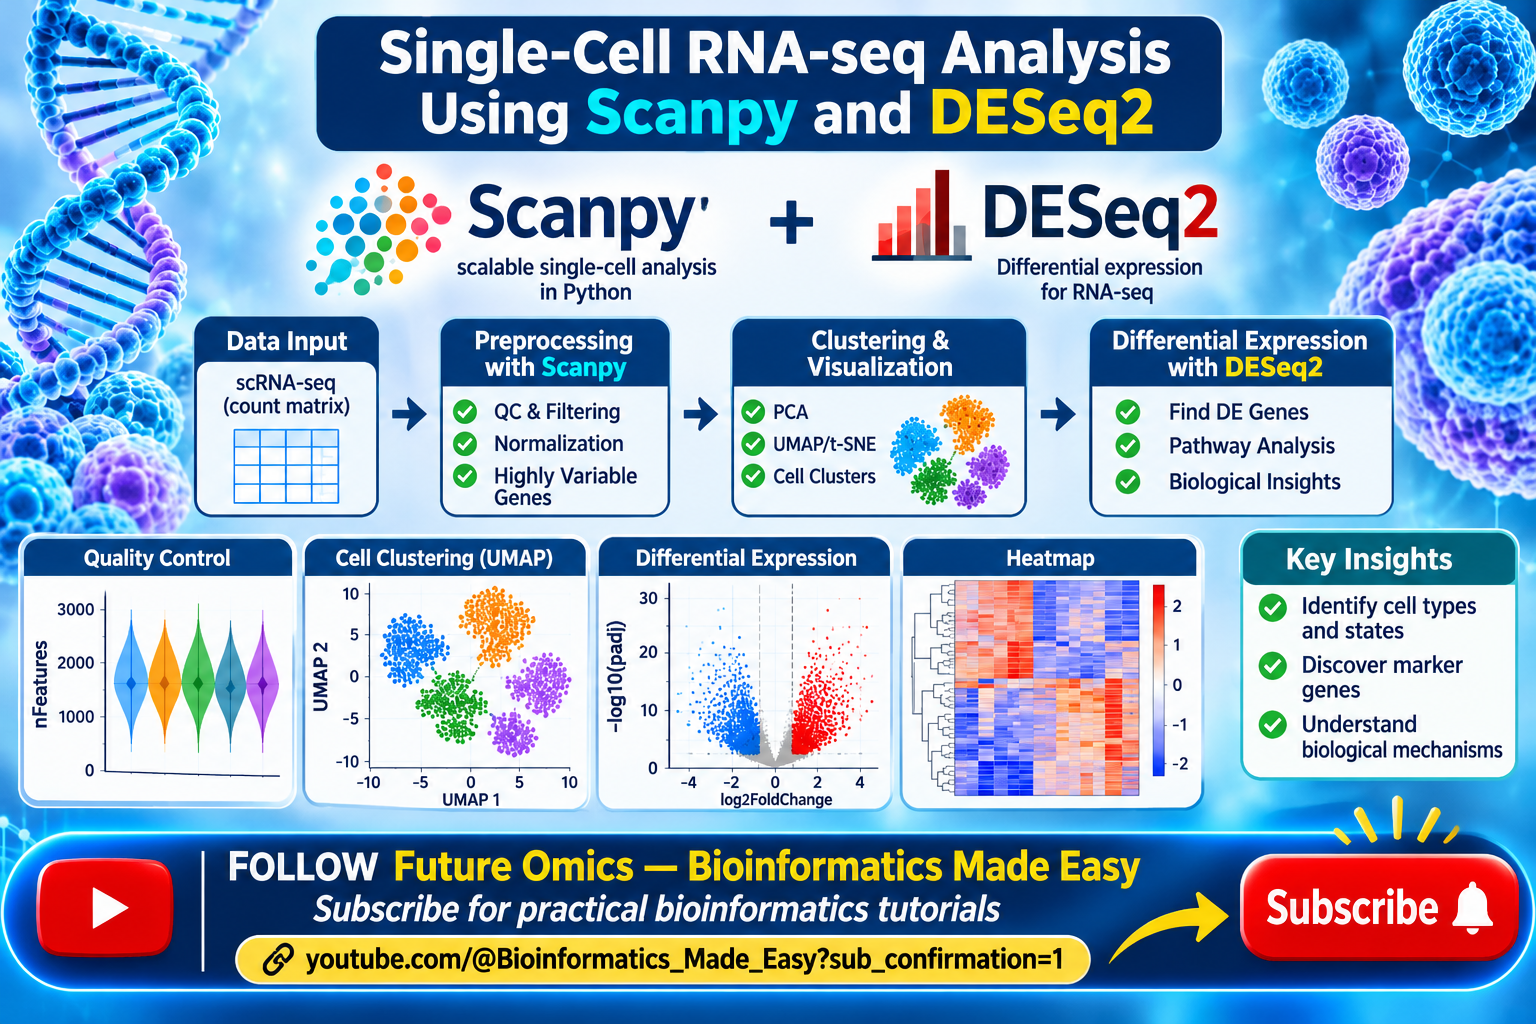

In [ ]:
!pip install -q scanpy anndata leidenalg igraph scrublet gseapy

In [ ]:
import os
import scanpy as sc
import anndata as ad
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

URL = "https://datasets.cellxgene.cziscience.com/8d7fad46-2f37-4aa0-ac9d-babbc36efb6f.h5ad"

!wget -q -O /content/GSE150728.h5ad "$URL"

adata = sc.read_h5ad("/content/GSE150728.h5ad")

print(adata)
print("Cells:", adata.n_obs)
print("Genes:", adata.n_vars)
print("Layers:", list(adata.layers.keys()))

print("\nCell metadata:")
print(adata.obs.head())

print("\nGene metadata:")
print(adata.var.head())

print("\nAvailable observation columns:")
print(adata.obs.columns.tolist())

AnnData object with n_obs × n_vars = 44721 × 24505
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type'
    uns: 'citation', 'is_pre_analysis', 'organism', 'organism_ontology_term_id', 'schema_reference', 'schema_version', 'title'
    obsm: 'X_pca', 'X_umap'
    layers: None (

Inspect raw counts and normalized expression

This step is particularly important for CELLxGENE datasets.

In [ ]:
def inspect_matrix(matrix, name):
    if sparse.issparse(matrix):
        values = matrix.data
    else:
        values = np.asarray(matrix).ravel()

    values = np.asarray(values)
    values = values[np.isfinite(values)]

    print("\n", name)
    print("Minimum:", values.min() if len(values) else None)
    print("Maximum:", values.max() if len(values) else None)
    print("Integer-like:",
          np.allclose(values[:10000],
                      np.round(values[:10000])) if len(values) else None)

inspect_matrix(adata.X, "adata.X")

for layer in adata.layers.keys():
    inspect_matrix(adata.layers[layer], layer)

if adata.raw is not None:
    inspect_matrix(adata.raw.X, "adata.raw.X")


 adata.X
Minimum: 0.6931472
Maximum: 7.449498
Integer-like: False

 None
Minimum: 0.6931472
Maximum: 7.449498
Integer-like: False

 adata.raw.X
Minimum: 1.0
Maximum: 1718.0
Integer-like: True


Main preprocessing pipeline
The following code automatically checks for a likely raw-count matrix. If none is found, it uses the existing expression matrix without re-normalizing it.

In [ ]:
# ==================================================
# GSE150728 PREPROCESSING
# ==================================================

OUTPUT = "/content/GSE150728_Results"
os.makedirs(OUTPUT, exist_ok=True)

# Select raw counts if available
count_matrix = None
count_source = None

def is_integer_matrix(matrix):
    if sparse.issparse(matrix):
        vals = matrix.data
    else:
        vals = np.asarray(matrix).ravel()

    vals = np.asarray(vals)
    vals = vals[np.isfinite(vals)]
    if len(vals) == 0:
        return False

    vals = vals[:min(10000, len(vals))]
    return np.allclose(vals, np.round(vals), atol=1e-5)

# First preference: counts layer
if "counts" in adata.layers:
    if is_integer_matrix(adata.layers["counts"]):
        count_matrix = adata.layers["counts"].copy()
        count_source = "layers:counts"

# Second preference: raw matrix
if count_matrix is None and adata.raw is not None:
    if is_integer_matrix(adata.raw.X):
        raw_names = pd.Index(adata.raw.var_names)

        if adata.var_names.isin(raw_names).all():
            count_matrix = adata.raw[:, adata.var_names].X.copy()
            count_source = "raw"

# Third preference: X
if count_matrix is None and is_integer_matrix(adata.X):
    count_matrix = adata.X.copy()
    count_source = "X"

print("Selected count source:", count_source)

# Work on a copy
adata = adata.copy()

if count_matrix is not None:

    adata.X = count_matrix.copy()
    adata.layers["counts"] = count_matrix.copy()

    # Mitochondrial gene identification
    adata.var["mt"] = (
        adata.var_names.str.upper().str.startswith("MT-")
    )

    # QC metrics on raw counts
    sc.pp.calculate_qc_metrics(
        adata,
        qc_vars=["mt"],
        percent_top=None,
        log1p=False,
        inplace=True
    )

    adata.obs.to_csv(
        f"{OUTPUT}/QC_metrics.csv"
    )

    # QC plots
    sc.pl.violin(
        adata,
        ["n_genes_by_counts",
         "total_counts",
         "pct_counts_mt"],
        multi_panel=True,
        show=False
    )

    plt.savefig(
        f"{OUTPUT}/QC_violin.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.close()

    # Filtering: adjust after inspecting QC distributions
    adata = adata[
        (adata.obs["n_genes_by_counts"] >= 200) &
        (adata.obs["n_genes_by_counts"] <= 6000) &
        (adata.obs["pct_counts_mt"] < 20)
    ].copy()

    sc.pp.filter_genes(adata, min_cells=3)

    # Normalize raw counts
    sc.pp.normalize_total(
        adata,
        target_sum=10000
    )

    sc.pp.log1p(adata)

else:

    print(
        "WARNING: Raw integer counts not identified. "
        "Using existing X without count normalization."
    )

    # Assumption: X is already log-normalized.
    # Confirm this using dataset documentation.
    adata = adata.copy()

    # Calculate detected genes only.
    # Total expression and mitochondrial percentages from
    # log-normalized values should not be interpreted as UMI QC.
    if sparse.issparse(adata.X):
        adata.obs["n_genes_detected"] = np.asarray(
            (adata.X > 0).sum(axis=1)
        ).ravel()
    else:
        adata.obs["n_genes_detected"] = (
            np.asarray(adata.X) > 0
        ).sum(axis=1)

    adata.obs.to_csv(
        f"{OUTPUT}/QC_metrics.csv"
    )

    # Do not apply raw-count QC thresholds or normalize again.

# Save normalized expression
adata.write_h5ad(
    f"{OUTPUT}/GSE150728_Preprocessed.h5ad"
)

print("Preprocessing completed:", adata)

Selected count source: raw
normalizing counts per cell
    finished (0:00:04)
Preprocessing completed: AnnData object with n_obs × n_vars = 44115 × 24505
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_typ

**Highly variable genes**

In [ ]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

adata.var[["highly_variable"]].to_csv(
    f"{OUTPUT}/Highly_Variable_Genes.csv"
)

sc.pl.highly_variable_genes(
    adata,
    show=False
)

plt.savefig(
    f"{OUTPUT}/HVG_plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.close()

extracting highly variable genes
    finished (0:00:03)


**PCA and UMAP**

In [ ]:
# Select highly variable genes
adata = adata[
    :, adata.var["highly_variable"]
].copy()

# Scaling
sc.pp.scale(
    adata,
    max_value=10
)

n_pcs = min(30, adata.n_vars - 1, adata.n_obs - 1)

sc.tl.pca(
    adata,
    n_comps=n_pcs
)

# PCA plot
sc.pl.pca_variance_ratio(
    adata,
    log=True,
    show=False
)

plt.savefig(
    f"{OUTPUT}/PCA_variance.png",
    dpi=300
)
plt.close()



computing PCA
    with n_comps=30
    finished (0:00:08)


COVID-19 versus healthy-control comparison
First inspect the available metadata:

In [ ]:
for col in adata.obs.columns:
    print("\n", col)
    print(adata.obs[col].value_counts().head(20))


 nCount_RNA
nCount_RNA
1080.0    48
1066.0    47
1022.0    47
1013.0    47
1033.0    45
1023.0    44
1051.0    44
1049.0    43
1011.0    42
1122.0    42
1019.0    41
1275.0    41
1010.0    40
1009.0    40
1246.0    40
1320.0    40
1436.0    40
1021.0    39
1231.0    39
1001.0    39
Name: count, dtype: int64

 nFeature_RNA
nFeature_RNA
772    74
839    71
709    70
865    70
767    69
652    68
715    68
728    68
731    68
729    67
756    67
792    67
686    66
698    66
725    66
788    66
783    66
805    66
658    65
778    65
Name: count, dtype: int64

 percent.mt
percent.mt
5.882353    22
5.555556    21
5.263158    20
6.666667    20
5.000000    19
7.142857    19
8.333333    18
3.703704    16
4.166667    16
7.692308    15
4.000000    15
9.090909    15
4.545455    14
4.761905    14
6.250000    14
6.896552    13
5.128205    12
5.405405    12
5.454545    12
9.523810    12
Name: count, dtype: int64

 percent.rps
percent.rps
0.000000    50
2.173913    24
1.960784    22
2.380952    21


Identify the correct disease-condition column and sample/patient identifier from the output.

For an initial exploratory comparison, you can use:

In [ ]:
# CHANGE THESE after inspecting adata.obs
GROUP_COLUMN = "disease"
GROUP1 = "COVID-19"
GROUP2 = "normal"

if GROUP_COLUMN not in adata.obs.columns:
    print("Change GROUP_COLUMN to the actual metadata column.")
else:

    subset = adata[
        adata.obs[GROUP_COLUMN].isin([GROUP1, GROUP2])
    ].copy()

    # Exploratory cell-level comparison, not pseudobulk.
    sc.tl.rank_genes_groups(
        subset,
        groupby=GROUP_COLUMN,
        groups=[GROUP1],
        reference=GROUP2,
        method="wilcoxon",
        use_raw=False
    )

    deg = sc.get.rank_genes_groups_df(
        subset,
        group=GROUP1
    )

    deg.to_csv(
        f"{OUTPUT}/COVID19_vs_Control_Exploratory_DEG.csv",
        index=False
    )

    print(deg.head(20))

ranking genes
    finished (0:00:13)
              names     scores  logfoldchanges          pvals      pvals_adj
0   ENSG00000143546  62.070206             NaN   0.000000e+00   0.000000e+00
1   ENSG00000157601  56.234093             NaN   0.000000e+00   0.000000e+00
2   ENSG00000165949  52.655739             NaN   0.000000e+00   0.000000e+00
3   ENSG00000038427  48.446335             NaN   0.000000e+00   0.000000e+00
4   ENSG00000137959  47.196220             NaN   0.000000e+00   0.000000e+00
5   ENSG00000126709  44.625187             NaN   0.000000e+00   0.000000e+00
6   ENSG00000111331  38.697491             NaN   0.000000e+00   0.000000e+00
7   ENSG00000142089  38.503273             NaN   0.000000e+00   0.000000e+00
8   ENSG00000211679  38.351959             NaN   0.000000e+00   0.000000e+00
9   ENSG00000121316  38.190769             NaN   0.000000e+00   0.000000e+00
10  ENSG00000090382  37.889332             NaN   0.000000e+00   0.000000e+00
11  ENSG00000025708  36.952515         

This is exploratory cell-level differential expression. For publication-grade disease comparisons, use patient-level pseudobulk counts and account for patient/sample replication and relevant covariates.

In [ ]:
# Export cell metadata
adata.obs.to_csv(
    f"{OUTPUT}/Cell_Metadata.csv"
)

# Export processed AnnData
adata.write_h5ad(
    f"{OUTPUT}/GSE150728_Final_Analysis.h5ad"
)

# Zip results
import shutil

shutil.make_archive(
    "/content/GSE150728_Results",
    "zip",
    OUTPUT
)

from google.colab import files

files.download(
    "/content/GSE150728_Results.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Inspect dataset metadata
First, identify sample IDs, disease conditions and cell annotations.

In [ ]:
import scanpy as sc
import pandas as pd
import numpy as np
from scipy import sparse

print("Dataset:", adata)

print("\nMetadata columns:")
print(adata.obs.columns.tolist())

print("\nSample metadata:")
for col in adata.obs.columns:
    print("\nCOLUMN:", col)
    print(adata.obs[col].value_counts().head(15))

Dataset: AnnData object with n_obs × n_vars = 44115 × 2000
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'n_cells

Save the metadata

In [ ]:
adata.obs.to_csv(
    f"{OUTPUT}/GSE150728_Cell_Metadata_Original.csv"
)

# **Quality control**
If your input contains raw counts, calculate standard QC metrics.

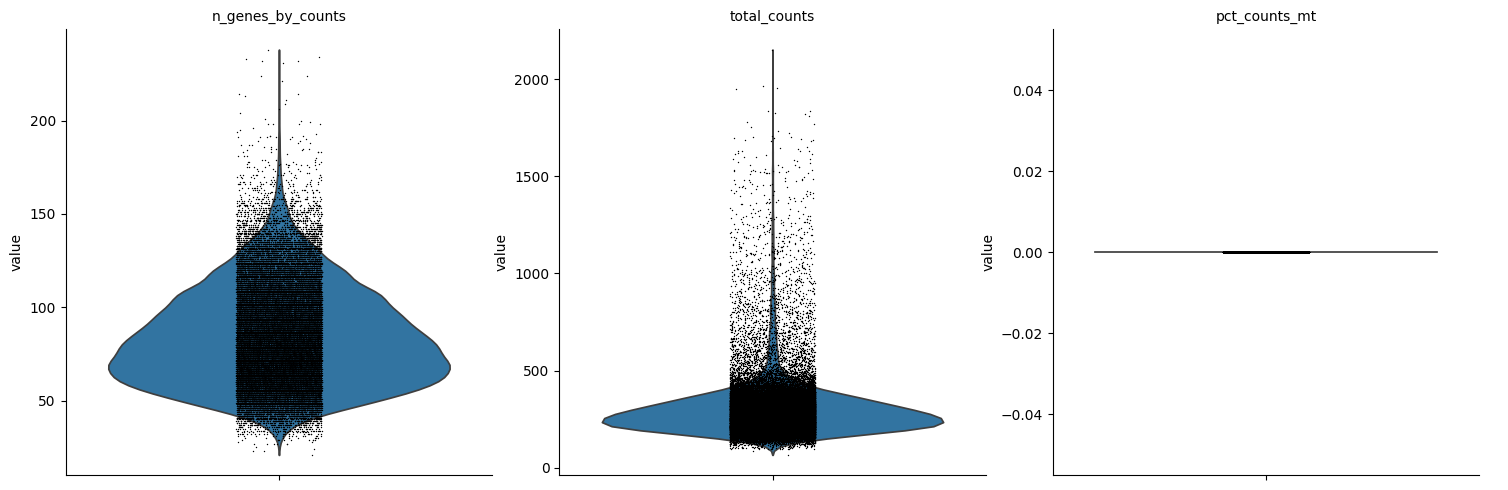

In [ ]:
# Identify mitochondrial genes
adata.var["mt"] = (
    adata.var_names.str.upper().str.startswith("MT-")
)

if "counts" in adata.layers:
    adata.X = adata.layers["counts"].copy()

sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# Export QC table
adata.obs.to_csv(
    f"{OUTPUT}/QC_Metrics.csv"
)

# QC visualization
sc.pl.violin(
    adata,
    ["n_genes_by_counts",
     "total_counts",
     "pct_counts_mt"],
    multi_panel=True,
    show=False
)

import matplotlib.pyplot as plt

plt.savefig(
    f"{OUTPUT}/QC_Violin.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# **Filter low-quality cells**
Run this section only when QC metrics were calculated from raw counts.

In [ ]:
# Adjust thresholds after reviewing QC plots

adata = adata[
    (adata.obs["n_genes_by_counts"] >= 200) &
    (adata.obs["n_genes_by_counts"] <= 6000) &
    (adata.obs["pct_counts_mt"] < 20)
].copy()

sc.pp.filter_genes(
    adata,
    min_cells=3
)

print("After filtering:", adata)

filtered out 1590 genes that are detected in less than 3 cells
After filtering: AnnData object with n_obs × n_vars = 18 × 410
    obs: 'nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'feature_is_filtered', 'feature_name', 'feature_reference', 'feature_biotype', 'feature_length', 'feature_type', 'mt', 'n_cells_by_counts

# **Normalize and log-transform**
For raw counts only:

In [ ]:
if "counts" not in adata.layers:
    adata.layers["counts"] = adata.X.copy()

adata.X = adata.layers["counts"].copy()

sc.pp.normalize_total(
    adata,
    target_sum=10000
)

sc.pp.log1p(adata)

adata.layers["log1p"] = adata.X.copy()

adata.write_h5ad(
    f"{OUTPUT}/GSE150728_Normalized.h5ad"
)

normalizing counts per cell
    finished (0:00:00)


If your dataset already contains log-normalized expression, skip this cell and retain that matrix in adata.layers["log1p"] after confirming its status.

# **Identify highly variable genes**

extracting highly variable genes
`n_top_genes` > `adata.n_var`, returning all genes.
    finished (0:00:00)


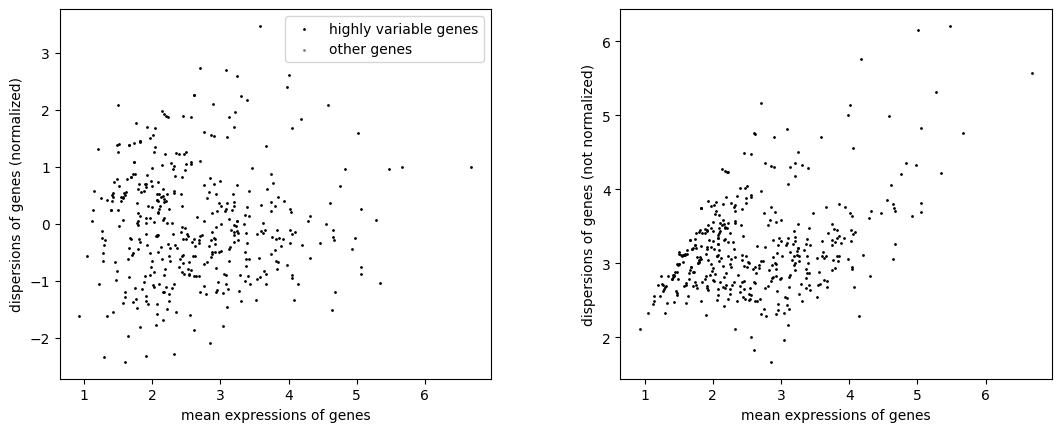

In [ ]:
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

hvg = adata.var[
    adata.var["highly_variable"]
]

hvg.to_csv(
    f"{OUTPUT}/Highly_Variable_Genes.csv"
)

sc.pl.highly_variable_genes(
    adata,
    show=False
)

plt.savefig(
    f"{OUTPUT}/HVG_Plot.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**PCA analysis**

computing PCA
    with n_comps=17
    finished (0:00:00)


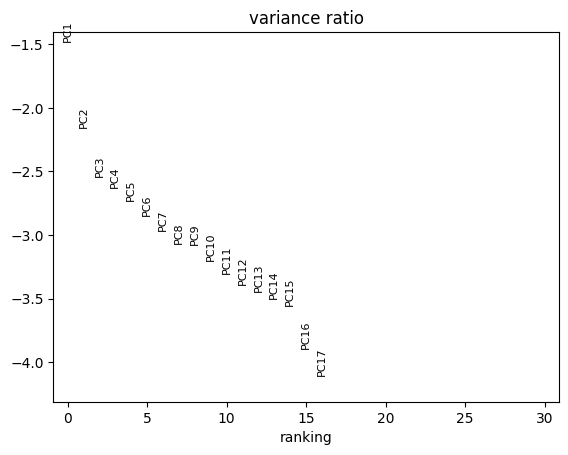

In [ ]:
adata = adata[
    :, adata.var["highly_variable"]
].copy()

sc.pp.scale(
    adata,
    max_value=10
)

n_pcs = min(
    30,
    adata.n_vars - 1,
    adata.n_obs - 1
)

sc.tl.pca(
    adata,
    n_comps=n_pcs
)

sc.pl.pca_variance_ratio(
    adata,
    log=True,
    show=False
)

plt.savefig(
    f"{OUTPUT}/PCA_Variance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**UMAP visualization**

computing neighbors
    using 'X_pca' with n_pcs = 17
    finished (0:00:19)
computing UMAP
    finished (0:00:00)


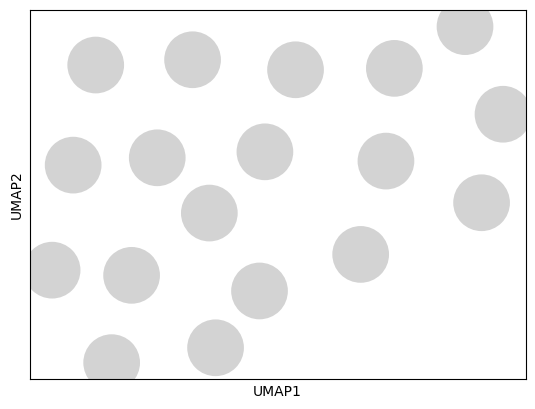

In [ ]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=n_pcs
)

sc.tl.umap(adata)

sc.pl.umap(
    adata,
    show=False
)

plt.savefig(
    f"{OUTPUT}/UMAP.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

**Leiden clustering**

running Leiden clustering
    finished (0:00:00)


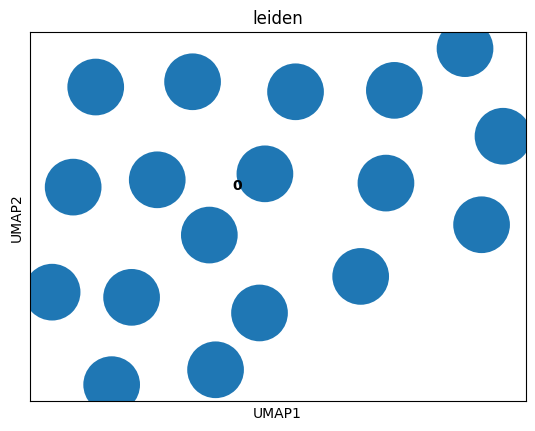

leiden
0    18
Name: count, dtype: int64


In [ ]:
sc.tl.leiden(
    adata,
    resolution=0.5,
    key_added="leiden"
)

sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",
    show=False
)

plt.savefig(
    f"{OUTPUT}/UMAP_Clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(adata.obs["leiden"].value_counts())

# **Identify cluster marker genes**
Use log-normalized, unscaled expression for marker testing.

In [ ]:
# Restore log-normalized expression
adata.X = adata.layers["log1p"].copy()

sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    use_raw=False
)

markers = sc.get.rank_genes_groups_df(
    adata,
    group=None
)

markers.to_csv(
    f"{OUTPUT}/Cluster_Marker_Genes.csv",
    index=False
)

print(markers.head(20))

ranking genes
    finished (0:00:04)
              names  scores  logfoldchanges  pvals  pvals_adj
0   ENSG00000204482     0.0             NaN    1.0        1.0
1   ENSG00000188906     0.0             NaN    1.0        1.0
2   ENSG00000189060     0.0             NaN    1.0        1.0
3   ENSG00000137959     0.0             NaN    1.0        1.0
4   ENSG00000130830     0.0             NaN    1.0        1.0
5   ENSG00000158856     0.0             NaN    1.0        1.0
6   ENSG00000102780     0.0             NaN    1.0        1.0
7   ENSG00000151023     0.0             NaN    1.0        1.0
8   ENSG00000010610     0.0             NaN    1.0        1.0
9   ENSG00000054793     0.0             NaN    1.0        1.0
10  ENSG00000166091     0.0             NaN    1.0        1.0
11  ENSG00000196787     0.0             NaN    1.0        1.0
12  ENSG00000138798     0.0             NaN    1.0        1.0
13  ENSG00000151748     0.0             NaN    1.0        1.0
14  ENSG00000109906     0.0      

**Cell-type annotation**
Use established marker genes to annotate clusters.

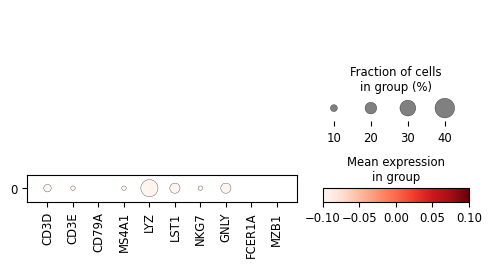

In [ ]:
sc.pl.dotplot(
    adata,
    var_names=[
        "CD3D", "CD3E",
        "CD79A", "MS4A1",
        "LYZ", "LST1",
        "NKG7", "GNLY",
        "FCER1A", "MZB1"
    ],
    groupby="leiden",
    gene_symbols="feature_name",
    standard_scale="var",
    show=False
)

plt.savefig(
    f"{OUTPUT}/Cell_Type_Marker_Dotplot.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

**Prepare pseudobulk count matrix**

This is the critical step for COVID-19 versus healthy-control DEG analysis.

First, check the available metadata columns:

In [ ]:
print(adata.obs.columns.tolist())

for col in adata.obs.columns:
    print("\n", col)
    print(adata.obs[col].value_counts().head(20))

['nCount_RNA', 'nFeature_RNA', 'percent.mt', 'percent.rps', 'percent.rpl', 'percent.rrna', 'nCount_SCT', 'nFeature_SCT', 'seurat_clusters', 'singler', 'cell.type.fine', 'cell.type.coarse', 'IFN1', 'HLA1', 'donor_id', 'DPS', 'DTF', 'Admission', 'Ventilated', 'tissue_ontology_term_id', 'assay_ontology_term_id', 'disease_ontology_term_id', 'cell_type_ontology_term_id', 'development_stage_ontology_term_id', 'self_reported_ethnicity_ontology_term_id', 'sex_ontology_term_id', 'is_primary_data', 'suspension_type', 'tissue_type', 'cell_type', 'assay', 'disease', 'sex', 'tissue', 'self_reported_ethnicity', 'development_stage', 'observation_joinid', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'leiden']

 nCount_RNA
nCount_RNA
2901.0     1
3984.0     1
4225.0     1
5799.0     1
4571.0     1
3064.0     1
6429.0     1
3966.0     1
10597.0    1
2828.0     1
3770.0     1
3818.0     1
6887.0     1
3671.0     1
3225.0     1
7588.0     1
12224.0    1
4950.0     1
Name: count

In [ ]:
SAMPLE_COL = "donor_id"
CONDITION_COL = "disease"
CELLTYPE_COL = "cell_type"

# If cell_type does not exist, use "leiden"

# **Generate pseudobulk counts**
The following code aggregates raw counts by biological sample and cell type.

In [ ]:
import scipy.sparse as sp

# CHANGE these names to match your metadata
SAMPLE_COL = "donor_id"
CONDITION_COL = "disease"
CELLTYPE_COL = "cell_type"

# Check metadata
required = [
    SAMPLE_COL,
    CONDITION_COL,
    CELLTYPE_COL
]

for col in required:
    if col not in adata.obs.columns:
        raise ValueError(
            f"{col} not found. Check adata.obs.columns."
        )

if "counts" not in adata.layers:
    raise ValueError(
        "Raw counts are required for pseudobulk DEG."
    )

# Raw counts
counts = adata.layers["counts"]

if sp.issparse(counts):
    counts = counts.tocsr()
else:
    counts = np.asarray(counts)

obs = adata.obs[
    [SAMPLE_COL, CONDITION_COL, CELLTYPE_COL]
].copy()

obs = obs.dropna()

# Aggregate by sample and cell type
pseudobulk_matrices = {}
pseudobulk_metadata = []

for (sample, condition, celltype), group in obs.groupby(
    [SAMPLE_COL, CONDITION_COL, CELLTYPE_COL],
    observed=True
):

    idx = adata.obs_names.get_indexer(group.index)
    idx = idx[idx >= 0]

    if len(idx) == 0:
        continue

    aggregated = counts[idx].sum(axis=0)

    if sp.issparse(aggregated):
        aggregated = aggregated.toarray()

    aggregated = np.asarray(aggregated).ravel()

    sample_key = f"{sample}_{celltype}"

    pseudobulk_matrices[sample_key] = aggregated

    pseudobulk_metadata.append({
        "sample": sample,
        "condition": condition,
        "cell_type": celltype,
        "n_cells": len(idx)
    })

pseudobulk_df = pd.DataFrame(
    pseudobulk_matrices,
    index=adata.var_names
)

pseudobulk_meta = pd.DataFrame(
    pseudobulk_metadata
).set_index("sample", drop=False)

pseudobulk_df.to_csv(
    f"{OUTPUT}/Pseudobulk_Counts.csv"
)

pseudobulk_meta.to_csv(
    f"{OUTPUT}/Pseudobulk_Sample_Metadata.csv"
)

print(pseudobulk_df.shape)
print(pseudobulk_meta.head())

(410, 8)
       sample condition   cell_type  n_cells
sample                                      
C1         C1  COVID-19    platelet        4
C1         C1  COVID-19  neutrophil        1
C3         C3  COVID-19    platelet        4
C4         C4  COVID-19    platelet        2
C7         C7  COVID-19    platelet        2


# **Differential gene expression using DESeq2**
For publication-grade pseudobulk DEG, use DESeq2 through R. This cell uses the pseudobulk count matrix generated above.

First, install R and DESeq2 in Colab:

In [ ]:
!apt-get update -qq
!apt-get install -y r-base
!R -e 'if (!requireNamespace("BiocManager", quietly=TRUE)) install.packages("BiocManager", repos="https://cloud.r-project.org"); BiocManager::install("DESeq2", ask=FALSE, update=FALSE)'

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
The following additional packages will be installed:
  r-base-core r-base-dev r-recommended
Suggested packages:
  elpa-ess r-doc-info | r-doc-pdf r-mathlib r-base-html texlive-base
  texlive-latex-base texlive-plain-generic texlive-fonts-recommended
  texlive-fonts-extra texlive-extra-utils texlive-latex-recommended
  texlive-latex-extra texinfo
Recommended packages:
  r-base-html r-doc-html
The following packages will be upgraded:
  r-base r-base-core r-base-dev r-recommended
4 upgraded, 0 newly installed, 0 to remove and 61 not upgraded.
Need to get 30.2 MB of archives.
After this operation, 76.8 kB of additional disk space will be used.
Get:1 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ r

**Save the pseudobulk files, then run:**

In [ ]:
pseudobulk_df.to_csv(
    "/content/Pseudobulk_Counts.csv"
)

pseudobulk_meta.to_csv(
    "/content/Pseudobulk_Metadata.csv",
    index=False
)

# **Use this R script to perform DESeq2 separately for each cell type:**

In [ ]:
%load_ext rpy2.ipython

In [ ]:
%%R
library(DESeq2)

counts <- read.csv(
  "/content/Pseudobulk_Counts.csv",
  row.names=1,
  check.names=FALSE
)

meta <- read.csv(
  "/content/Pseudobulk_Metadata.csv",
  stringsAsFactors=FALSE
)

# Example conditions; CHANGE to actual metadata labels
CASE <- "COVID-19"
CONTROL <- "normal"

OUTPUT <- "/content/GSE150728_Results"
dir.create(OUTPUT, showWarnings=FALSE, recursive=TRUE)

# Loop over cell types
for (ct in unique(meta$cell_type)) {

  selected <- meta$cell_type == ct &
    meta$condition %in% c(CASE, CONTROL)

  m <- meta[selected, ]

  # Require at least two biological samples per group;
  # three or more is preferable.
  group_counts <- table(m$condition)

  if (!all(c(CASE, CONTROL) %in% names(group_counts))) next

  if (group_counts[CASE] < 2 ||
      group_counts[CONTROL] < 2) next

  sample_columns <- paste(m$sample, m$cell_type, sep="_")

  if (!all(sample_columns %in% colnames(counts))) next

  count_mat <- as.matrix(counts[, sample_columns, drop=FALSE])

  storage.mode(count_mat) <- "integer"

  # Remove genes with no meaningful expression
  keep <- rowSums(count_mat >= 10) >= 2
  count_mat <- count_mat[keep, , drop=FALSE]

  m$condition <- factor(
    m$condition,
    levels=c(CONTROL, CASE)
  )

  rownames(m) <- sample_columns

  m <- m[colnames(count_mat), , drop=FALSE]

  dds <- DESeqDataSetFromMatrix(
    countData=count_mat,
    colData=m,
    design=~condition
  )

  dds <- DESeq(dds)

  res <- results(
    dds,
    contrast=c("condition", CASE, CONTROL)
  )

  result_df <- as.data.frame(res)

  result_df$gene <- rownames(result_df)

  result_df <- result_df[
    order(result_df$padj, na.last=TRUE),
  ]

  write.csv(
    result_df,
    file=file.path(
      OUTPUT,
      paste0("DEG_", gsub("[^A-Za-z0-9_-]", "_", ct), ".csv")
    ),
    row.names=FALSE
  )

  message("Completed cell type: ", ct)
}

Loading required package: S4Vectors
Loading required package: stats4
Loading required package: BiocGenerics
Loading required package: generics

Attaching package: ‘generics’

The following objects are masked from ‘package:base’:

    as.difftime, as.factor, as.ordered, intersect, is.element, setdiff,
    setequal, union


Attaching package: ‘BiocGenerics’

The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs

The following objects are masked from ‘package:base’:

    anyDuplicated, aperm, append, as.data.frame, basename, cbind,
    colnames, dirname, do.call, duplicated, eval, evalq, Filter, Find,
    get, grep, grepl, is.unsorted, lapply, Map, mapply, match, mget,
    order, paste, pmax, pmax.int, pmin, pmin.int, Position, rank,
    rbind, Reduce, rownames, sapply, saveRDS, table, tapply, unique,
    unsplit, which.max, which.min


Attaching package: ‘S4Vectors’

The following object is masked from ‘package:utils’:

    findMatches

The following object

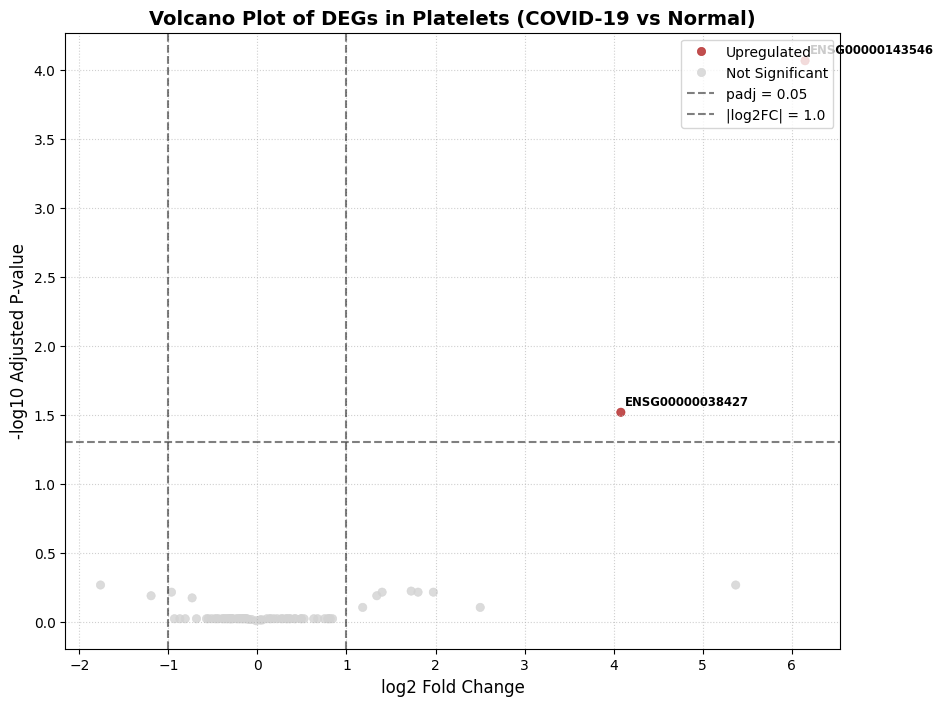

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load the DEG results
deg_path = "/content/GSE150728_Results/DEG_platelet.csv"
deg_df = pd.read_csv(deg_path)

# Filter out rows with missing p-values or log2FoldChange
deg_df = deg_df.dropna(subset=['log2FoldChange', 'padj'])

# Calculate -log10(padj)
deg_df['-log10_padj'] = -np.log10(deg_df['padj'])

# Define thresholds for significance
padj_threshold = 0.05
lfc_threshold = 1.0

# Annotate genes based on thresholds
def annotate_significance(row):
    if row['padj'] < padj_threshold and row['log2FoldChange'] > lfc_threshold:
        return 'Upregulated'
    elif row['padj'] < padj_threshold and row['log2FoldChange'] < -lfc_threshold:
        return 'Downregulated'
    else:
        return 'Not Significant'

deg_df['Significance'] = deg_df.apply(annotate_significance, axis=1)

# Create the Volcano Plot
plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=deg_df,
    x='log2FoldChange',
    y='-log10_padj',
    hue='Significance',
    palette={'Upregulated': 'firebrick', 'Downregulated': 'navy', 'Not Significant': 'lightgray'},
    alpha=0.8,
    edgecolor=None
)

# Add threshold lines
plt.axhline(-np.log10(padj_threshold), color='black', linestyle='--', alpha=0.5, label=f'padj = {padj_threshold}')
plt.axvline(lfc_threshold, color='black', linestyle='--', alpha=0.5)
plt.axvline(-lfc_threshold, color='black', linestyle='--', alpha=0.5, label=f'|log2FC| = {lfc_threshold}')

# Label top significant genes
top_genes = deg_df[deg_df['padj'] < padj_threshold].nsmallest(10, 'padj')
for _, row in top_genes.iterrows():
    plt.text(
        row['log2FoldChange'] + 0.05,
        row['-log10_padj'] + 0.05,
        row['gene'],
        horizontalalignment='left',
        size='small',
        color='black',
        weight='semibold'
    )

plt.title('Volcano Plot of DEGs in Platelets (COVID-19 vs Normal)', fontsize=14, weight='bold')
plt.xlabel('log2 Fold Change', fontsize=12)
plt.ylabel('-log10 Adjusted P-value', fontsize=12)
plt.legend(loc='upper right')
plt.grid(True, linestyle=':', alpha=0.6)

# Save the plot
volcano_plot_path = "/content/GSE150728_Results/Platelet_Volcano_Plot.png"
plt.savefig(volcano_plot_path, dpi=300, bbox_inches='tight')
plt.show()

In [ ]:
import pandas as pd

# Load the DEG results
deg_path = "/content/GSE150728_Results/DEG_platelet.csv"
deg_df = pd.read_csv(deg_path)

# Apply the filters: padj < 0.01 and log2FoldChange > 2.0
filtered_deg = deg_df[(deg_df['padj'] < 0.01) & (deg_df['log2FoldChange'] > 2.0)].copy()

# Sort by statistical significance
filtered_deg = filtered_deg.sort_values(by='padj')

# Save to a new CSV file
filtered_output_path = "/content/GSE150728_Results/DEG_platelet_significant_upregulated.csv"
filtered_deg.to_csv(filtered_output_path, index=False)

print(f"Filtering complete. Saved {len(filtered_deg)} genes to {filtered_output_path}.")
display(filtered_deg)

Filtering complete. Saved 1 genes to /content/GSE150728_Results/DEG_platelet_significant_upregulated.csv.


,baseMean,log2FoldChange,lfcSE,stat,pvalue,padj,gene
0,16.313121,6.148842,1.265288,4.85964,0.000001,0.000086,ENSG00000143546


# **DEG results interpretation**
Your final DEG CSV will contain:


Column	Meaning

1. baseMean	Average normalized expression
2. log2FoldChange	Expression change
3. lfcSE	Standard error
4. stat	Statistical test statistic
5. pvalue	Raw p-value
6. padj	Multiple-testing adjusted p-value




In [ ]:
import glob

deg_files = glob.glob(
    "/content/GSE150728_Results/DEG_*.csv"
)

for file in deg_files:

    df = pd.read_csv(file)

    significant = df[
        (df["padj"] < 0.05) &
        (df["log2FoldChange"].abs() >= 1)
    ]

    significant.to_csv(
        file.replace(".csv", "_Significant.csv"),
        index=False
    )

    print(
        os.path.basename(file),
        "Significant DEGs:",
        len(significant)
    )

DEG_platelet.csv Significant DEGs: 2
DEG_platelet_significant_upregulated.csv Significant DEGs: 1
